In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("mexwell/fake-reviews-dataset")

print("Path to dataset files:", path)

100%|██████████| 4.78M/4.78M [00:01<00:00, 3.52MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/mexwell/fake-reviews-dataset/versions/1


In [2]:
import pandas as pd
import os

pat1 = os.path.join(path, "fake reviews dataset.csv")

df = pd.read_csv(pat1)
df

,category,rating,label,text_
0,Home_and_Kitchen_5,5.0,CG,"Love this! Well made, sturdy, and very comfor..."
1,Home_and_Kitchen_5,5.0,CG,"love it, a great upgrade from the original. I..."
2,Home_and_Kitchen_5,5.0,CG,This pillow saved my back. I love the look and...
3,Home_and_Kitchen_5,1.0,CG,"Missing information on how to use it, but it i..."
4,Home_and_Kitchen_5,5.0,CG,Very nice set. Good quality. We have had the s...
...,...,...,...,...
40427,Clothing_Shoes_and_Jewelry_5,4.0,OR,I had read some reviews saying that this bra r...
40428,Clothing_Shoes_and_Jewelry_5,5.0,CG,I wasn't sure exactly what it would be. It is ...
40429,Clothing_Shoes_and_Jewelry_5,2.0,OR,"You can wear the hood by itself, wear it with ..."
40430,Clothing_Shoes_and_Jewelry_5,1.0,CG,I liked nothing about this dress. The only rea...


In [3]:
print(df.info())
print(df.isnull().sum())
print(df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40432 entries, 0 to 40431
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   category  40432 non-null  object 
 1   rating    40432 non-null  float64
 2   label     40432 non-null  object 
 3   text_     40432 non-null  object 
dtypes: float64(1), object(3)
memory usage: 1.2+ MB
None
category    0
rating      0
label       0
text_       0
dtype: int64
12


In [4]:

print(df.columns.tolist())


['category', 'rating', 'label', 'text_']


In [5]:

TEXT_COL = "text_"
LABEL_COL = "label"

df = df[[TEXT_COL, LABEL_COL]].copy()
df.columns = ["text", "label"]

df = df.dropna()
df["text"] = df["text"].astype(str).str.strip()
df = df[df["text"] != ""]
df = df.drop_duplicates()

print(df.shape)
print(df["label"].value_counts())
display(df.head())


(40410, 2)
label
OR    20215
CG    20195
Name: count, dtype: int64


,text,label
0,"Love this! Well made, sturdy, and very comfor...",CG
1,"love it, a great upgrade from the original. I...",CG
2,This pillow saved my back. I love the look and...,CG
3,"Missing information on how to use it, but it i...",CG
4,Very nice set. Good quality. We have had the s...,CG


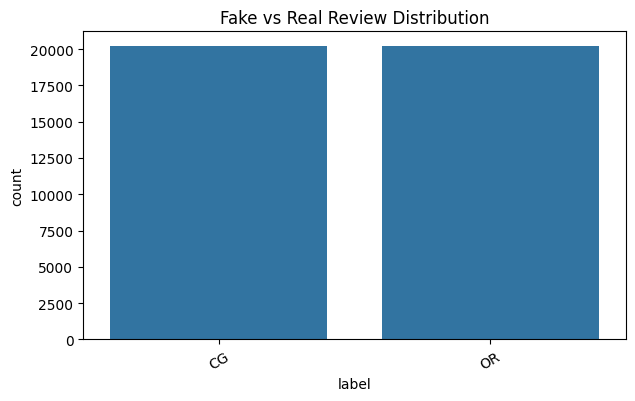

In [6]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="label")
plt.title("Fake vs Real Review Distribution")
plt.xticks(rotation=30)
plt.show()


In [7]:

import re
import nltk

nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = re.sub(r"<.*?>", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    words = text.split()
    words = [
        lemmatizer.lemmatize(word)
        for word in words
        if word not in stop_words
    ]
    return " ".join(words)

df["clean_text"] = df["text"].apply(preprocess_text)

display(df[["text", "clean_text", "label"]].head())


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


,text,clean_text,label
0,"Love this! Well made, sturdy, and very comfor...",love well made sturdy comfortable love pretty,CG
1,"love it, a great upgrade from the original. I...",love great upgrade original mine couple year,CG
2,This pillow saved my back. I love the look and...,pillow saved back love look feel pillow,CG
3,"Missing information on how to use it, but it i...",missing information use great product price,CG
4,Very nice set. Good quality. We have had the s...,nice set good quality set two month,CG


In [8]:
from sklearn.model_selection import train_test_split

X = df["clean_text"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 32328
Testing rows: 8082


In [9]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC

model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=30000,
        ngram_range=(1, 2),
        min_df=2,
        sublinear_tf=True
    )),
    ("classifier", LinearSVC(random_state=42))
])

model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


Accuracy: 0.9102944815639693

Classification Report:

              precision    recall  f1-score   support

          CG       0.91      0.91      0.91      4039
          OR       0.91      0.91      0.91      4043

    accuracy                           0.91      8082
   macro avg       0.91      0.91      0.91      8082
weighted avg       0.91      0.91      0.91      8082



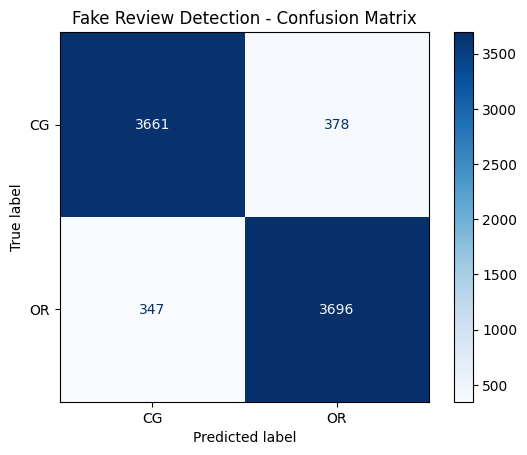

In [10]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model.classes_
).plot(cmap="Blues")

plt.title("Fake Review Detection - Confusion Matrix")
plt.show()

In [11]:

new_review = "The product is excellent and works exactly as described."

clean_review = preprocess_text(new_review)

prediction = model.predict([clean_review])[0]

print("Review:", new_review)
print("Predicted label:", prediction)


Review: The product is excellent and works exactly as described.
Predicted label: OR


In [12]:
import joblib

joblib.dump(model, "fake_review_nlp_model.pkl")

print("Model saved successfully!")

Model saved successfully!
